# A02 · 상관관계 전환구간과 실제 급등·급락: 정의 · 정렬 · 우연 비교 · 사례

**Track A · Phase A3**. A01·A012 에서 만든 상관 변화 후보(C)가 가격 급등·급락 후보(P)와 **시간적으로 가까운가**, 가깝다면 **우연 이상인가**,
그리고 그 근접이 **같은 날 수익률 하나가 두 번 세어진 기계적 결과**는 아닌가를 검증한다.

**전제 (연구 정책)**
- **Correlation Change ≠ Ground Truth Price Surge.** 어떤 P 정의도 정답(Ground Truth)이 아니다. 일치율은 '탐지 정확도'가 아니라 두 사건 집합의 시간적 중첩이다.
- 근접은 인과가 아니다. 사후에 확정된 사건(`confirmed_at` > `candidate_at`, P4 누적)은 실시간 신호가 아니다.
- 2019-2024 개발 · 2025 검증 · 2026 관찰 구간. 2026 은 기존 EDA 가 이미 본 데이터라 **blind holdout 이 아니다**. 2026 에 맞춰 기준을 바꾸지 않았다.

**무거운 계산(사건 생성 · 46,000 검정 × B=1000, p≤0.01 은 B=20000)** 은 `a3_pipeline.run_a3()` 의 checkpoint 를 쓴다.
checkpoint 는 입력 데이터 버전·코드 해시·표 해시가 모두 현재와 일치할 때만 로드된다(불일치 시 오류). 핵심 값 하나는 이 노트북에서 다시 계산해 대조한다.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "research_a_contract.yaml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.kfont import setup_korean_font
from src.r2h.research_a import contract as K, data as D, qa as Q
from src.r2h.research_a import rolling_correlation as RC, robustness as RB, visualization as V
from src.r2h.research_a import correlation_events as CE, price_events as PE, event_matching as EM

setup_korean_font()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

C = K.load_contract(ROOT)
VERSION = K.input_data_version(D.read_manifest(C))
REF = C.reference
SPEC = D.etf_manifest(C).set_index("ticker")
LAB = {t: f"{t} {SPEC.at[t, 'name']}" for t in SPEC.index}
FIG_DIR = ROOT / "reports" / "r2h" / "research_a" / "figures" / "A02"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    p = FIG_DIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight", dpi=110)
    return p

assert D.verify_raw_sha(C)["match"].all(), "raw sha mismatch"
r = D.returns(C, "dq_trim_canonical")      # 실제 데이터 · 일간 로그수익률(logdiff) · 261240 DQ 2일 NaN
rr = D.returns(C, "raw")                   # DQ 처리 없음 (민감도용)
close = D.load_close_panel(C)              # KRW, 20종 공통 거래일
print("ROOT:", ROOT, "| input_version:", VERSION[:16], "| sha:", K.git_sha(ROOT)[:10], "| r:", r.shape, r.index[0].date(), "~", r.index[-1].date())

ROOT: /home/sieg/projects-wsl/hongik_univ_26_2/SA/.worktrees/SA_ETF/codex-a | input_version: fd9713f7f985e950 | sha: 95b93ea846 | r: (1902, 20) 2019-01-03 ~ 2026-10-02


In [2]:
from src.r2h.research_a.a3_pipeline import load_a3_checkpoint, c_subsets, SEED, P_TEST_DEFS
ck = load_a3_checkpoint(ROOT)                      # 불일치면 RuntimeError
print("checkpoint:", ck["manifest"]["run_id"], ck["status"])
ce, pe, T = ck["correlation_event_candidates"], ck["price_event_candidates"], ck["event_null_tests"]
ce["window_n"] = pd.to_numeric(ce["window"], errors="coerce")
COMP = [t for t in C.base_panel if t not in (REF, "102110")]
assert all(ck["status"].values())

checkpoint: A3-20261011T150723-fd9713f7 {'input_version_match': True, 'code_hash_match': True, 'table_hash_match': True, 'all_tables_present': True}


## 1. 두 종류의 사건과 네 개의 시점

| 필드 | 상관 사건 C | 가격 사건 P |
|---|---|---|
| `candidate_at` | 후보가 처음 관측된 거래일 (예: band 밖 첫날) | 사건 시작일 (`event_start`) |
| `confirmed_at` | 지속성 등 조건 충족일 (C3: k 번째 날) | 정의가 충족된 날 (`identified_at`; P4 누적은 시작 + h − 1) |
| `available_at` | 실시간으로 '사건'이라 말할 수 있는 최초 시점 = `confirmed_at` | = `confirmed_at` |
| `event_end` | 다음 전환 직전 / 초과 구간 끝 | 사건 구간 끝 |

**왜 구분하나.** C3 의 `candidate_at` 은 *나중에 지속됐다는 것을 알고 나서* 붙인 날짜다. 이를 실시간 신호처럼 쓰면 미래 정보를 쓴 것이다.
P4(누적 h 일)도 같다 — 시작일에는 앞으로 h 일 동안 오를지 알 수 없다(`posthoc_label: true`).

In [3]:
lag_c = (ce.confirmed_at - ce.candidate_at).dt.days
lag_p = (pe.available_at - pe.candidate_at).dt.days
tl = pd.concat([ce.assign(gap=lag_c).groupby("definition_id").gap.describe()[["count", "mean", "max"]],
                pe.assign(gap=lag_p).groupby("definition_id").gap.describe()[["count", "mean", "max"]]])
tl.columns = ["n_events", "mean_calendar_days_candidate_to_available", "max"]
display(tl.round(1))
assert (pe[pe.definition_id.str.startswith("P4")].available_at > pe[pe.definition_id.str.startswith("P4")].candidate_at).all()
assert (ce[ce.definition_id == "C1_zero_cross"].available_at == ce[ce.definition_id == "C1_zero_cross"].candidate_at).all()
assert abs(tl.loc["C3_sign_regime", "mean_calendar_days_candidate_to_available"] - 11.1) < 0.1

,n_events,mean_calendar_days_candidate_to_available,max
definition_id,,,
C1_zero_cross,1572.0,0.0,0.0
C2_large_change,1208.0,0.0,0.0
C3_sign_regime,1023.0,11.1,35.0
C4_multi_window,287.0,13.0,45.0
P1_vol_scaled,618.0,0.0,0.0
P2_quantile_exp,1199.0,0.0,0.0
P2_quantile_full,798.0,0.0,0.0
P3_rz_A,1217.0,0.0,0.0
P3_rz_D,1108.0,0.0,0.0


**해석**: C1·C2·P1·P2·P3·P5 는 후보일 = 확인일(그날 종가로 판단 가능). C3 는 평균 **11.1 달력일**(최대 35), C4 13.0일, P4 는 h5 6.1 · h10 13.7 · h20 28.6 달력일 늦게 확인된다.
이 차이 때문에 §5 에서 **candidate_at 기준**과 **confirmed_at 기준**을 따로 검정한다.

> **재구성 질문** — 같은 사건의 `candidate_at` 과 `available_at` 사이에 가격 급등이 있었다면, 그 일치는 왜 '조기 탐지'의 증거가 될 수 없는가?

## 2. 상관 사건 정의 C1 ~ C5

| ID | 정의 | 무엇을 측정하나 | 실시간 |
|---|---|---|---|
| C1 `zero_cross` | $\mathrm{sign}\rho_t\ne\mathrm{sign}\rho_{t-1}$ | 0선을 넘는 모든 움직임 (잡음 포함) | ○ |
| C2 `large_change` | $z_t=\frac{\operatorname{atanh}\rho_t-\operatorname{atanh}\rho_{t-w}}{\sqrt{2/(w-3)}}$, $|z|>2.58$ | 비겹침 창 대비 상관 *크기*의 급변 (부호 무관) | ○ |
| C3 `sign_regime` | $|\rho|>b$ 같은 부호 $k$ 일 연속 (primary b=0.1, k=10) | 지속된 부호 전환 | candidate ✗ / confirmed ○ |
| C4 `multi_window` | C3 또는 C2 가 서로 다른 창 ≥2 개에서 ±10 일 안 같은 방향 | 창 간 동시 변화 | confirmed ○ |
| C5 `method_concordant` | C3 가 Pearson·Spearman 양쪽에서 ±5 일 안 같은 방향 | 추정량에 덜 의존하는 전환 | confirmed ○ |

C2 의 Fisher z 는 두 창이 겹치지 않고 독립·정규일 때 표준정규 근사다. 꼬리·변동성 군집이 있으면 |z| 가 과대될 수 있다.
C5 는 지시문 원문에 정의가 남아 있지 않아(누락) A 가 정의했다 — 계약 `adopted_A2_A3.correlation_events.C5`.

In [4]:
c69 = ce[ce.reference_series_id == REF]
cnt = (c69[c69.method == "pearson"].groupby(["definition_id", "series_id"]).size().unstack(fill_value=0))
display(cnt.rename(columns=LAB))
c5 = CE.c5_method_concordant(c69[c69.definition_id == "C3_sign_regime"].assign(window=lambda d: pd.to_numeric(d.window)), r.index)
c5p = c5[c5.parameter_set.str.contains('"band": 0.1, "persist": 10')]
print("C5 (primary C3 기준) 사건 수:", len(c5p)); display(c5p.groupby(["series_id", "window"]).size().unstack(fill_value=0))
c3p = c69[(c69.definition_id == "C3_sign_regime") & (c69.method == "pearson") & (c69.parameter_set == '{"band": 0.1, "persist": 10}')]
print("C3 primary (pearson) 사건 수:", len(c3p), "· 그중 102110 대조:", (c3p.series_id == "102110").sum())
assert len(c5p) == 51 and (c3p.series_id == "102110").sum() == 0 and len(c3p) == 111
assert c3p.groupby("series_id").size().to_dict() == {"132030": 17, "148070": 41, "153130": 30, "261220": 21, "261240": 2}

series_id,102110 TIGER 200,132030 KODEX 골드선물(H),133690 TIGER 미국나스닥100,148070 KIWOOM 국고채10년,153130 KODEX 단기채권,219480 KODEX 미국S&P500선물(H),229200 KODEX 코스닥150,261220 KODEX WTI원유선물(H),261240 KODEX 미국달러선물
definition_id,,,,,,,,,
C1_zero_cross,0,145,32,141,254,2,0,115,12
C2_large_change,81,62,69,70,27,62,90,68,64
C3_sign_regime,0,82,10,158,165,0,0,98,16
C4_multi_window,9,24,7,36,28,7,7,26,5


C5 (primary C3 기준) 사건 수: 51


window,30,60,120
series_id,,,
132030,7,2,1
148070,14,3,0
153130,8,6,0
261220,8,0,0
261240,2,0,0


C3 primary (pearson) 사건 수: 111 · 그중 102110 대조: 0


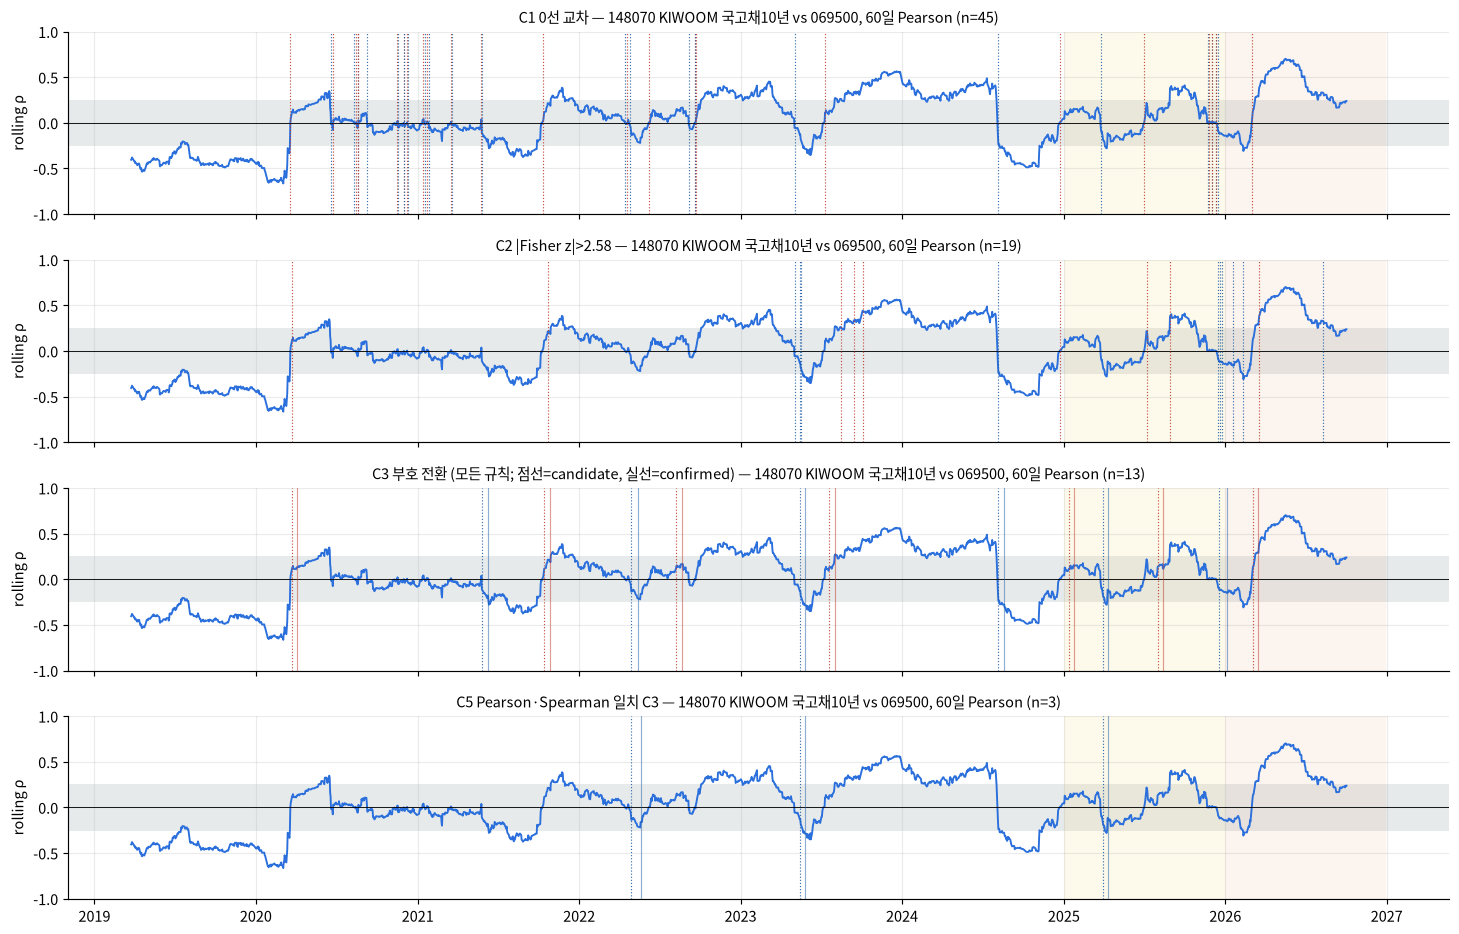

In [5]:
t, w = "148070", 60
rho = RC.rolling_corr(r[t], r[REF], w, min_periods=54)["rho"]
sub = lambda d: c69[(c69.series_id == t) & (c69.window == str(w)) & (c69.method == "pearson") & (c69.definition_id == d)]
fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for a, (d, ttl) in zip(ax, [("C1_zero_cross", "C1 0선 교차"), ("C2_large_change", "C2 |Fisher z|>2.58"),
                            ("C3_sign_regime", "C3 부호 전환 (모든 규칙; 점선=candidate, 실선=confirmed)"), (None, "C5 Pearson·Spearman 일치 C3")]):
    ev = sub(d) if d else c5p[(c5p.series_id == t) & (c5p.window == w)]
    if d == "C3_sign_regime":
        ev = ev[ev.parameter_set == '{"band": 0.1, "persist": 10}']
    V.rho_panel(a, {w: rho}, title=f"{ttl} — {LAB[t]} vs 069500, {w}일 Pearson (n={len(ev)})", band_window=w, events=ev, legend=False)
    V.shade_periods(a)
fig.tight_layout(); savefig(fig, "01_C_definitions_148070_w60"); plt.show()

### 해석
- **본 것**: 069500 기준 Pearson 사건 수(3창 합, C3 는 4개 규칙 합)는 정의마다 크게 다르다. C1 은 148070 141 · 153130 254 · 132030 145 · 261220 115 건,
  C3 primary(b0.1, k10)는 148070 41 · 153130 30 · 261220 21 · 132030 17 · 261240 2 건(합 111)으로 줄고,
  229200·219480·133690 은 C3 가 **0건**(A012 §4: 상관이 항상 양). C5 는 51건 — C3 의 Pearson 사건 중 Spearman 에서도 보이는 것만 남는다.
- **102110 은 C3 0건**: 같은 지수라 ρ≈0.998 로 부호가 안 바뀐다. 대조 ETF 는 사건 비교 대상이 아니라 강건성 확인용이다.
- **의미**: 이후 모든 일치율은 "어떤 C 정의, 어떤 창"에 대한 것인지 함께 읽어야 한다.

> **재구성 질문** — C2(크기 급변)와 C3(부호 전환)는 같은 날 발생할 수 있는가? 둘이 측정하는 것의 차이를 수식으로 설명하라.

## 3. 가격 사건 정의 P1 ~ P5 — 급등(+1)과 급락(−1)은 따로

| ID | 정의 | 실시간 | 메모 |
|---|---|---|---|
| P1 `vol_scaled` | $r_t/\sigma_{t-1}^{(60)}\ge 3$ (σ 는 shift(1)) | ○ | 과거 변동성 대비 큰 움직임 |
| P2 `quantile_exp` / `_full` | $r_t\ge q_{0.99}(r_{\le t-1})$ (expanding, 최소 250) / 전체표본 $q_{0.99}$ | ○ / **✗ look-ahead** | full 은 서술용 |
| P3 `rz_D` / `rz_A` / `rz_eda` | 기존 robust-z 3 정의 그대로 (A1 레지스트리), $z\ge3$ | ○ | **어느 것도 정답으로 선언하지 않음** |
| P4 `cum_h{5,10,20}` | $\sum_{s=t}^{t+h-1} r_s/(\sigma_{t-1}\sqrt h)\ge2.5$, 연속 시작일 병합 | **✗ 사후 라벨** | `available_at` = 시작 + h − 1 |
| P5 `legacy_abs3` / `q99` / `common_shock` | SHOCK_MAP: |log r|>3%(부호 분리), |r|>q99(look-ahead), rz3_D dedup 동반 ≥5 | ○ / ✗ / ○ | 공통충격 40일 = SHOCK_MAP 재현 |

direction,급락(−1),급등(+1)
definition_id,,
P1_vol_scaled,18,10
P2_quantile_exp,44,41
P2_quantile_full,20,20
P3_rz_A,36,15
P3_rz_D,34,11
P3_rz_eda,36,13
P4_cum_h10,13,14
P4_cum_h20,12,10
P4_cum_h5,19,17


공통충격일(P5_common_shock): 40 일 — SHOCK_MAP_FINAL rz3_D dedup k≥5 = 40


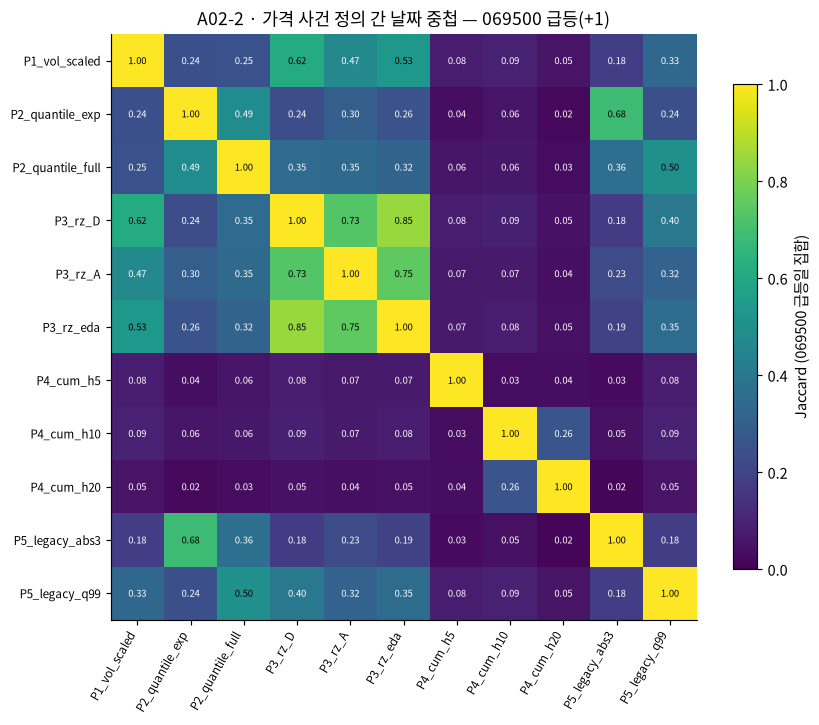

,def_a,def_b,n_a,n_b,jaccard
0,P3_rz_D,P3_rz_eda,11,13,0.846
1,P3_rz_A,P3_rz_D,15,11,0.733
2,P3_rz_A,P3_rz_eda,15,13,0.750


In [6]:
pc = pe.groupby(["series_id", "definition_id", "direction"]).size().unstack(["direction"], fill_value=0)
display(pc.loc[[REF]].droplevel(0).rename(columns={-1: "급락(−1)", 1: "급등(+1)"}))
print("공통충격일(P5_common_shock):", int((pe.definition_id == "P5_common_shock").sum()), "일 — SHOCK_MAP_FINAL rz3_D dedup k≥5 = 40")
jac = ck["price_def_jaccard"]; j69 = jac[jac.series_id == REF]
M = pd.DataFrame(np.nan, index=P_TEST_DEFS[:-1], columns=P_TEST_DEFS[:-1])
for x in j69.itertuples():
    M.loc[x.def_a, x.def_b] = M.loc[x.def_b, x.def_a] = x.jaccard
for dd in M.index:
    M.loc[dd, dd] = 1.0          # pandas 3 CoW: .values 는 읽기 전용
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(M.values, cmap="viridis", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(M))); ax.set_xticklabels(M.columns, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=8)
for i in range(len(M)):
    for j in range(len(M)):
        ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="w" if M.values[i, j] < .5 else "k")
fig.colorbar(im, shrink=.8, label="Jaccard (069500 급등일 집합)"); ax.set_title("A02-2 · 가격 사건 정의 간 날짜 중첩 — 069500 급등(+1)")
savefig(fig, "02_P_jaccard"); plt.show()
rz = ck["robust_z_definition_overlap"]; display(rz[rz.series_id == REF][["def_a", "def_b", "n_a", "n_b", "jaccard"]].round(3))
assert int((pe.definition_id == "P5_common_shock").sum()) == 40
rz69 = rz[rz.series_id == REF].set_index(["def_a", "def_b"])
assert abs(rz69.loc[("P3_rz_A", "P3_rz_D"), "jaccard"] - 0.733) < 2e-3 and abs(rz69.loc[("P3_rz_D", "P3_rz_eda"), "jaccard"] - 0.846) < 2e-3

### 해석
- **본 것**: 069500 급등일 수는 정의마다 10(P1)~55(abs3)일. 급락이 급등보다 많은 정의가 대부분이다(P1 18 vs 10, rz_D 34 vs 11).
- **robust-z 세 정의**: 급등일 rz_A 15 · rz_D 11 · rz_eda 13, Jaccard **0.73 (A–D) · 0.75 (A–eda) · 0.85 (D–eda)**. MAD 정의(창 내부 vs 잔차 rolling median)와 min_periods 만 바꿔도
  급등일의 1/4 이 바뀐다. 기존 SHOCK_MAP 의 "DEFINITION_DEPENDENT" 판정을 개별 ETF 수준에서 재확인.
- **정의 간 거리**: P4(누적) 와 일간 정의의 Jaccard 는 0.02~0.09 — '며칠에 걸친 상승'과 '하루 급등'은 거의 다른 날이다.
- **의미**: "가격 급등"은 하나의 사건 집합이 아니다. 아래 일치율은 P 정의마다 따로 보고, 정의 하나를 골라 정답이라 하지 않는다.

> **재구성 질문** — rz_A 와 rz_D 가 같은 날에 대해 다른 판단을 내리는 경로를 MAD 계산식 차이로 설명하라.

## 4. 사건 매칭 — 일대일, 시간차, 유형

$\text{lag}=\mathrm{pos}(P.\text{candidate\_at})-\mathrm{pos}(C.\text{candidate\_at})$ [거래일]. $|\text{lag}|\le L$ 인 쌍을 |lag| 가 작은 순서로 **일대일** 매칭한다
(한 P 가 여러 C 에 중복 계산되지 않음).

| 유형 | 조건 |
|---|---|
| `co_occur` | lag = 0 |
| `corr_leads` | lag > 0 — 상관 사건이 먼저 |
| `price_leads` | lag < 0 — 가격 사건이 먼저 |
| `corr_only` / `price_only` | 짝 없음 |
| `dq_uncertain` | C 또는 P 창에 경로 영향 DQ flag (유형과 별도 집계) |

**예시 (SAMPLE)**: C 가 10·12·60일, P 가 11·90일이면 L=5 에서 (C10 or C12, P11) 중 하나만 매칭된다.

,c_event_id,p_event_id,c_date,p_date,lag,match_type,dq_uncertain
0,c10,p11,2020-01-15,2020-01-16,1.0,corr_leads,False
1,c12,NaN,2020-01-17,NaT,NaN,corr_only,False
2,c60,NaN,2020-03-25,NaT,NaN,corr_only,False
3,NaN,p90,NaT,2020-05-06,NaN,price_only,False


{'n_C': 3, 'n_P': 2, 'n_matched': 1, 'share_C_matched': 0.3333333333333333, 'share_P_matched': 0.5, 'n_co_occur': 0, 'n_corr_leads': 1, 'n_price_leads': 0, 'n_corr_only': 2, 'n_price_only': 1, 'n_dq_uncertain': 0, 'lag_median': 1.0, 'lag_mean': 1.0}


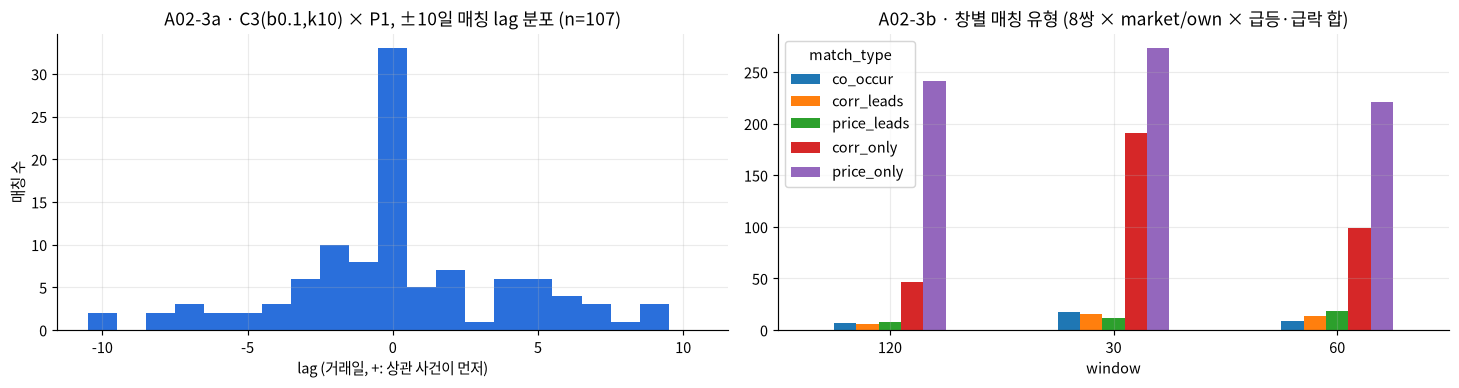

match_type,co_occur,corr_leads,corr_only,price_leads,price_only
window,,,,,
120,7,6,47,8,241
30,17,16,191,12,273
60,9,14,99,18,221


lag=0 비중: 0.308 · lag>0: 0.336 · lag<0: 0.355


In [7]:
idx = pd.bdate_range("2020-01-01", periods=100)
toyC = pd.DataFrame({"event_id": ["c10", "c12", "c60"], "candidate_at": idx[[10, 12, 60]], "quality_flag": [None] * 3})
toyP = pd.DataFrame({"event_id": ["p11", "p90"], "candidate_at": idx[[11, 90]], "quality_flag": [None] * 2})
mt = EM.match_events(toyC, toyP, idx, 5); display(mt); print(EM.summarize_matches(mt, 3, 2))
al = ck["event_alignment"]
a1 = al[(al.c_def == "C3_b0.100_k10") & (al.p_def == "P1_vol_scaled")]
lags = a1.lag.dropna()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].hist(lags, bins=np.arange(-10.5, 11.5, 1), color="#2a6fdb"); ax[0].set_xlabel("lag (거래일, +: 상관 사건이 먼저)"); ax[0].set_ylabel("매칭 수")
ax[0].set_title(f"A02-3a · C3(b0.1,k10) × P1, ±10일 매칭 lag 분포 (n={len(lags)})")
vc = a1.groupby(["window", "match_type"]).size().unstack(fill_value=0)
vc[["co_occur", "corr_leads", "price_leads", "corr_only", "price_only"]].plot.bar(ax=ax[1], rot=0); ax[1].set_title("A02-3b · 창별 매칭 유형 (8쌍 × market/own × 급등·급락 합)")
fig.tight_layout(); savefig(fig, "03_lag_distribution"); plt.show()
display(vc)
print("lag=0 비중:", round((lags == 0).mean(), 3), "· lag>0:", round((lags > 0).mean(), 3), "· lag<0:", round((lags < 0).mean(), 3))
LAG0 = float((lags == 0).mean())
assert abs(LAG0 - 0.308) < 3e-3 and abs((lags > 0).mean() - 0.336) < 3e-3 and abs((lags < 0).mean() - 0.355) < 3e-3

### 해석
- 매칭된 쌍의 **31%** 가 lag = 0 한 값에 몰린다(단일 lag 로는 최빈). 나머지는 ±10일 안에 넓게 퍼지며 상관이 먼저(lag>0) **34%**, 가격이 먼저(lag<0) **36%** 로 비슷하다 —
  "상관 변화가 급등을 선행한다"는 패턴은 보이지 않는다.
- 압도적인 유형은 `corr_only` 와 `price_only` 다: 대부분의 C3 는 ±10일 안에 P1 이 없고, 대부분의 P1 은 C3 와 무관하다.
- **lag 0 의 의미**: 같은 날 일치는 §6 에서 보듯 상당 부분 기계적이다.

> **재구성 질문** — lag=0 매칭이 많다는 사실만으로 "상관 변화와 급등이 같은 원인을 공유한다"고 말할 수 없는 이유는?

## 5. 우연 수준 비교 — circular shift 귀무검정과 다중비교

**귀무가설 H0**: C 와 P 의 시간 배치는 서로 무관하다(각자의 군집 구조는 그대로).
**방법**: P 의 위치 전체를 같은 offset $u$ 만큼 원형 이동 → P 내부의 간격·군집은 보존, C 와의 상대 위치만 무작위화. $u\sim U\{2L+1,\dots,n-2L-1\}$.
**통계량**: $T$ = ±L 안에 P 가 하나라도 있는 C 의 수. **p 값**: $p=(1+\#\{T^{*}\ge T_{obs}\})/(B+1)$ — 유한 표본에서 0 이 되지 않는 Monte Carlo 규칙.
**seed** 20261011, B=1000. p ≤ 0.01 인 검정은 같은 귀무·통계량으로 **B=20000 재추정** (seed+1).

**왜 재추정이 필요한가 (A1~A3 중간 보고 정정)**: B=1000 의 최소 p 는 1/1001 ≈ 0.001. 45,280 개 가설에 BH 를 적용하면 가장 작은 p 가 통과하려면
$p\le 0.10/45{,}280\approx2.2\times10^{-6}$ 이어야 한다 — B=1000 으로는 **원리적으로 불가능**하다. 중간 보고의 "BH 후 유의 결과 없음"은 이 해상도 한계였다.
재추정은 기준 변경이 아니라 같은 p 의 정밀도를 높인 것이다(B=20000 최소 p ≈ 5×10⁻⁵).

**검정 수의 정확한 의미**: 46,000 행 = 기본 조건 5,750 (C 정의 8 × 쌍 × 창 × P 대상 × P 정의 × 방향) × 사건 시점 2 (candidate/confirmed) × L 4 (0,5,10,20).
이 중 C 또는 P 가 0 건인 720 행은 귀무분포가 퇴화하므로 BH 에서 제외(검정 가능 45,280).
**의존성 경고**: 같은 C 집합이 L·시점·P 정의마다 재사용되므로 검정들은 강하게 양(+)의 의존을 가진다 → 'p<0.05 비율'은 독립 시행의 5% 와 직접 비교할 수 없다.
BH 는 양의 의존(PRDS)에서 FDR 을 통제하지만, 이 구조가 PRDS 를 만족하는지 증명하지는 않았다.

In [8]:
row = T[(T.c_def == "C3_b0.100_k10") & (T.ticker == "148070") & (T.window == "60") & (T.p_target == "market") & (T.p_def == "P1_vol_scaled")
        & (T.p_direction == -1) & (T.c_time == "candidate_at") & (T.max_lag == 10)].iloc[0]
cs = c_subsets(ce.assign(window=ce.window_n)[ce.method == "pearson"])["C3_b0.100_k10"]
Cx = cs[(cs.series_id == "148070") & (cs.window == 60)]
Px = pe[(pe.series_id == REF) & (pe.definition_id == "P1_vol_scaled") & (pe.direction == -1)]
posm = pd.Series(np.arange(len(r.index)), index=r.index)
res = EM.circular_shift_test_fast(posm[Cx.candidate_at].to_numpy(), posm[Px.candidate_at].to_numpy(), len(r.index), 10,
                                  B=int(row.B_used), seed=SEED if row.B_used == 1000 else SEED + 1)
print("checkpoint:", {k: row[k] for k in ["T_obs", "T_null_mean", "p_value", "B_used"]}); print("재계산  :", {k: res[k] for k in ["T_obs", "T_null_mean", "p_value", "B"]})
assert res["T_obs"] == row.T_obs and abs(res["p_value"] - row.p_value) < 1e-9   # CSV 는 %.10g 저장

checkpoint: {'T_obs': np.int64(5), 'T_null_mean': np.float64(1.958), 'p_value': np.float64(0.01798201798), 'B_used': np.int64(1000)}
재계산  : {'T_obs': 5, 'T_null_mean': 1.958, 'p_value': 0.017982017982017984, 'B': 1000}


n_tests  share_p<0.05  n_q<0.10(global)  median_T_obs/T_null
c_time       max_lag                                                              
candidate_at 0         5660.0         0.143              69.0                0.000
             5         5660.0         0.086              16.0                1.367
             10        5660.0         0.067              35.0                1.261
             20        5660.0         0.048              42.0                1.186
confirmed_at 0         5660.0         0.080              15.0                0.000
             5         5660.0         0.073              33.0                0.975
             10        5660.0         0.069              36.0                1.114
             20        5660.0         0.054              53.0                1.154

{'n_tests': 46000, 'n_tests_testable': 45280, 'n_simulated_shifts_total': 65646000, 'n_refined_B20000': 1034, 'min_p_value': 4.999750012499375e-05, 'min_q_global': 0.008640789334579072, 'n_tests_q_lt_0.10': 299, 'n_primary_family': 586, 'min_q_primary': 0.009766178357748779, 'n_primary_q_lt_0.10': 3}


,c_def,ticker,window,p_target,p_def,p_direction,n_C,n_P,T_obs,T_null_mean,p_value,q_value_bh_primary
17058,C3_b0.100_k10,153130,120,market,P4_cum_h20,1,6,10,3,0.52755,0.00005,0.009766
19130,C3_b0.100_k10,261220,60,universe,P5_common_shock,-1,5,29,4,0.99595,0.00005,0.009766
19810,C3_b0.100_k10,261240,30,own,P4_cum_h20,1,2,9,2,0.16750,0.00005,0.009766


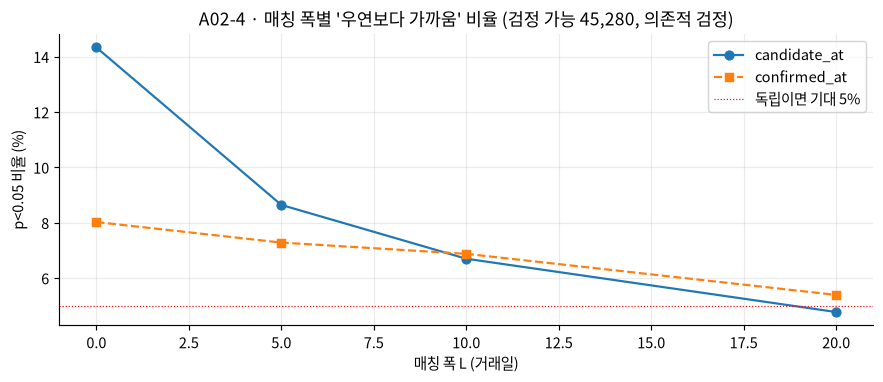

In [9]:
tt = T[T.testable]
summ = tt.groupby(["c_time", "max_lag"]).apply(lambda g: pd.Series({"n_tests": len(g), "share_p<0.05": (g.p_value < .05).mean(),
                                                                   "n_q<0.10(global)": int((g.q_value_bh < .10).sum()),
                                                                   "median_T_obs/T_null": g.ratio_obs_null.median()}))
display(summ.round(3))
m = ck["manifest"]["metrics"]
print({k: m[k] for k in ["n_tests", "n_tests_testable", "n_simulated_shifts_total", "n_refined_B20000", "min_p_value", "min_q_global",
                         "n_tests_q_lt_0.10", "n_primary_family", "min_q_primary", "n_primary_q_lt_0.10"]})
pri = tt[tt.primary_family]
display(pri[pri.q_value_bh_primary < .10][["c_def", "ticker", "window", "p_target", "p_def", "p_direction", "n_C", "n_P", "T_obs", "T_null_mean", "p_value", "q_value_bh_primary"]])
fig, ax = plt.subplots(figsize=(10, 3.6))
for ct, mk in (("candidate_at", "o-"), ("confirmed_at", "s--")):
    s = tt[tt.c_time == ct].groupby("max_lag").apply(lambda g: (g.p_value < .05).mean())
    ax.plot(s.index, s * 100, mk, label=ct)
ax.axhline(5, c="r", lw=.8, ls=":", label="독립이면 기대 5%"); ax.set_xlabel("매칭 폭 L (거래일)"); ax.set_ylabel("p<0.05 비율 (%)"); ax.legend()
ax.set_title("A02-4 · 매칭 폭별 '우연보다 가까움' 비율 (검정 가능 45,280, 의존적 검정)"); savefig(fig, "04_null_share_by_lag"); plt.show()
assert m["n_tests"] == 46000 and m["n_tests_testable"] == 45280 and m["n_tests_q_lt_0.10"] == 299 and m["n_primary_q_lt_0.10"] == 3
assert abs((tt[tt.max_lag == 0].p_value < .05).mean() - 0.112) < 2e-3 and abs((tt[tt.max_lag == 20].p_value < .05).mean() - 0.051) < 2e-3

### 해석
- **재계산 일치**: checkpoint 의 한 검정(148070 · 60일 · C3 × 069500 급락 P1 · L=10)을 같은 seed 로 다시 돌려 $T_{obs}$·p 가 정확히 같다.
- **매칭 폭별**: p<0.05 비율은 L=0 **11.2%** → L=5 8.0% → L=10 6.8% → L=20 **5.1%**. 폭을 넓힐수록 우연 수준(5%)에 수렴한다.
  `confirmed_at` 기준(실시간으로 알 수 있는 시점)은 L=0 에서 이미 낮다(그림).
- **BH (정밀화 후)**: 검정 가능 45,280 중 global q<0.10 **299 개**(최소 q 0.0086), 그중 84 개가 L=0. 사전 지정 1차 가족
  (C3 b0.1 k10 × candidate_at × L=10, 586 검정)에서는 **3 개**만 q<0.10 이며, 셋 다 C 사건이 2~6 개뿐인 조합
  (153130 120일 × 069500 P4_h20 급등 · 261220 60일 × 공통충격 급락 · 261240 30일 × 자기 P4_h20 급등)이다 — 사건 수가 적어 한두 번의 우연한 근접에도 p 가 작아진다.
- **의미**: "상관 변화 후보가 가격 사건 근처에 우연보다 자주 온다"는 주장은 **L=0(같은 날)에서만 일관되게** 성립하고, 매칭 폭을 넓히거나 실시간 시점으로 바꾸면 약해진다.
  다음 절은 그 L=0 효과의 정체를 본다.

> **재구성 질문** — B=1000 에서 BH 통과가 원리적으로 불가능했던 이유를 최소 p 와 BH 임계값으로 계산해 보여라.

## 6. 같은 날 일치의 기계적 성분 — leave-event-days-out

두 가지로 본다.
1. **진입일 영향**(A01 §6): C1·C3 후보일에 *오늘 하루*를 빼면 교차가 사라지는가.
2. **사건일 제거 재검정**: 069500 P1 사건일(급등·급락 28일)의 수익률을 **두 시리즈 모두** NaN 으로 두고 C3 를 다시 만든 뒤, 같은 P1 집합과의 근접을 다시 검정한다(B=2000).
   P 는 원래 날짜에 그대로 있으므로, 남는 근접은 "그날 수익률 없이도 상관이 이미 바뀌고 있었다"는 뜻이다.

In [10]:
ms = ck["mechanical_summary"]; display(ms.drop(columns=["run_id", "input_data_version"]).round(3))
mr = ck["mechanical_removed_retest"]
mrs = mr.groupby("max_lag").agg(n_tests=("ticker", "size"), T_obs_orig=("T_obs_orig", "sum"), T_obs_masked=("T_obs_masked", "sum"),
                                n_p05_orig=("p_value_orig", lambda s: int((s < .05).sum())), n_p05_masked=("p_value_masked", lambda s: int((s < .05).sum())))
display(mrs)
assert mrs.loc[0, "n_p05_orig"] == 9 and mrs.loc[0, "n_p05_masked"] == 0 and mrs.loc[0, "T_obs_orig"] == 18 and mrs.loc[0, "T_obs_masked"] == 1
assert ms.set_index(["c_def", "window"]).loc[("C3_b0.100_k10", "60"), "share_driven_given_same_day"] == 1.0

,c_def,window,n,share_entering_day_driven,share_same_day_P1_any,n_same_day_P1,share_driven_given_same_day
0,C1_zero_cross,30,382,0.484,0.110,42,0.857
1,C1_zero_cross,60,207,0.469,0.111,23,0.870
2,C1_zero_cross,120,112,0.527,0.125,14,0.929
3,C3_b0.100_k10,30,59,0.542,0.220,13,0.923
4,C3_b0.100_k10,60,35,0.457,0.200,7,1.000
5,C3_b0.100_k10,120,17,0.588,0.353,6,0.833


,n_tests,T_obs_orig,T_obs_masked,n_p05_orig,n_p05_masked
max_lag,,,,,
0,48,18,1,9,0
5,48,43,22,3,2
10,48,53,33,3,0
20,48,62,52,2,0


### 해석
- **진입일 영향**: C1 교차의 47~53%, C3 후보의 46~59% 는 그날 하루 수익률이 만든 것이다. 같은 날 P1 이 있었던 C3 로 좁히면 **83~100%** (60일 창 7/7).
- **사건일 제거**: P1 사건일 28일을 지우고 C3 를 다시 만들면, L=0 근접 C3 수가 **18 → 1**, p<0.05 검정이 **9/48 → 0/48**. L=10 도 3 → 0, L=20 2 → 0.
- **결론**: 같은 날의 "상관 전환 + 가격 급변" 일치는 **같은 큰 수익률을 두 번 센 기계적 결과**로 거의 전부 설명된다.
  상관 변화를 급등의 독립 신호(또는 Ground Truth)로 쓰는 것을 지지하지 않는다.

> **재구성 질문** — 사건일을 NaN 으로 둔 재검정이 '같은 날 수익률의 영향 제거'로서 갖는 장점과, 그로 인해 잃는 정보는 무엇인가?

## 7. 사례 — ETF 쌍별 독립 선정

사례는 쌍마다 독립적으로 고른다(같은 쌍 안에서 같은 날짜를 두 유형에 쓰지 않음). 유형이 없는 쌍은 **'없음'으로 기록**한다.
기준: C = C3(b0.1, k10, Pearson), P = 069500·자기 자신의 P1 및 공통충격 P5. `corr_only`·`price_only`·`window_dependent` 는 ±20 거래일.

In [11]:
cases = ck["case_study_index"]
display(cases.drop(columns=["run_id", "input_data_version"]))
print("발견:", int(cases.found.sum()), "· 없음:", int((~cases.found).sum()))
display(cases.pivot_table(index="ticker", columns="case_type", values="found", aggfunc="sum").fillna(0).astype(int))
f = cases[cases.found]
assert not f.duplicated(["ticker", "c_date", "p_date"]).any() and int(cases.found.sum()) == 32 and int((~cases.found).sum()) == 19

,case_id,ticker,window,case_type,c_date,p_date,lag,found,reason
0,CASE01,148070,60,co_occur,2024-08-05,2024-08-05,0.0,True,"C3 candidate 와 P1 이 같은 거래일 (w60, market P1, la..."
1,CASE02,148070,60,corr_leads,2026-03-04,2026-03-05,1.0,True,"C3 candidate 가 P1 보다 먼저 (w60, market P1, lag +1)"
2,CASE03,148070,60,price_leads,2020-03-23,2020-03-20,-1.0,True,"P1 이 C3 candidate 보다 먼저 (w60, market P1, lag -1)"
3,CASE04,148070,30,corr_only,2023-04-03,NaT,NaN,True,w30 C3 (직전 강도 |ρ|=0.50) — ±20일 안 P1·P3_rz_D·P4...
4,CASE05,148070,NaN,price_only,NaT,2020-01-28,NaN,True,P5_common_shock UNIVERSE (−) — 이 쌍의 C1·C2·C3 가...
5,CASE06,148070,30,window_dependent,2020-03-19,NaT,NaN,True,w30 C3 있으나 ±20일 안 w120 C3 없음
6,CASE07,153130,60,co_occur,2020-03-24,2020-03-24,0.0,True,"C3 candidate 와 P1 이 같은 거래일 (w60, market P1, la..."
7,CASE08,153130,60,corr_leads,2021-06-22,2021-06-28,4.0,True,"C3 candidate 가 P1 보다 먼저 (w60, own P1, lag +4)"
8,CASE09,153130,60,price_leads,2025-01-03,2025-01-02,-1.0,True,"P1 이 C3 candidate 보다 먼저 (w60, own P1, lag -1)"
9,CASE10,153130,30,corr_only,2023-07-19,NaT,NaN,True,w30 C3 (직전 강도 |ρ|=0.45) — ±20일 안 P1·P3_rz_D·P4...


발견: 32 · 없음: 19


case_type,co_occur,corr_leads,corr_only,dq_affected,price_leads,price_only,window_dependent
ticker,,,,,,,
132030,1,1,1,0,1,1,1
133690,0,0,0,0,0,1,0
148070,1,1,1,0,1,1,1
153130,1,1,1,1,1,0,1
219480,0,0,0,1,0,1,0
229200,0,0,0,0,0,1,0
261220,1,1,1,0,1,1,1
261240,0,0,1,1,0,1,1


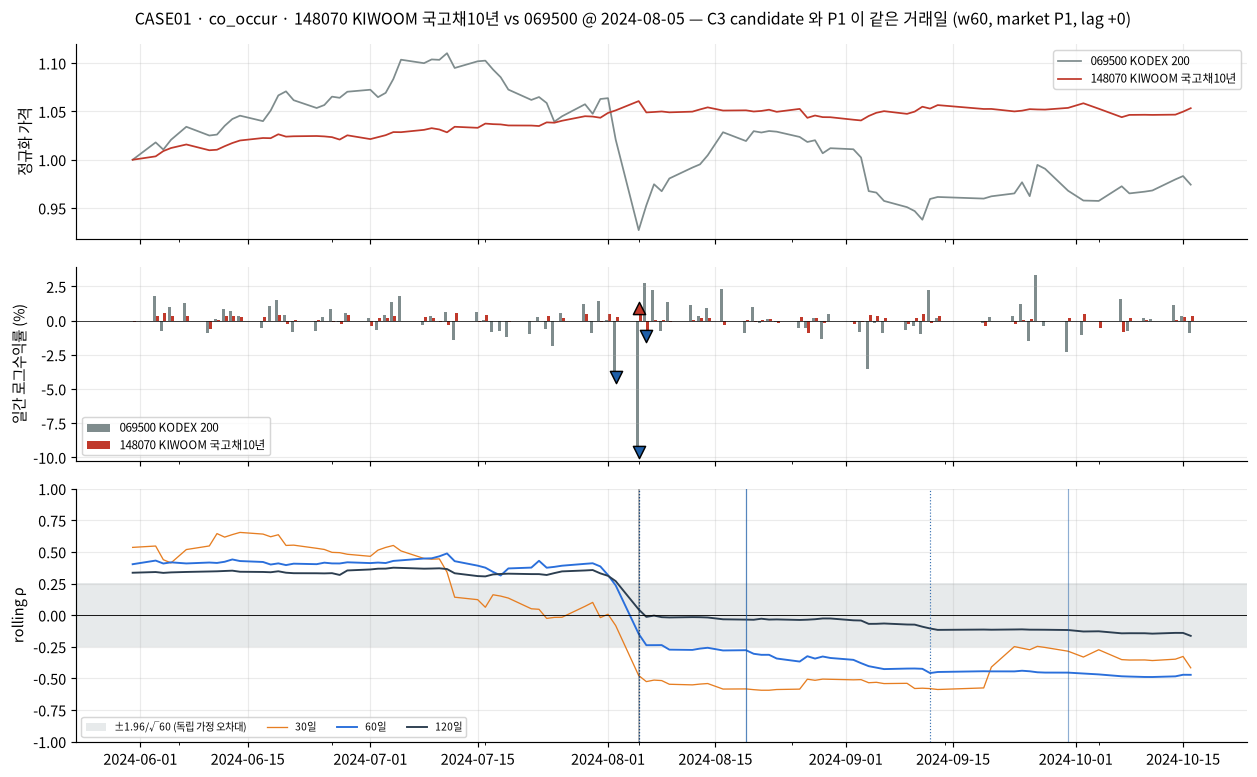

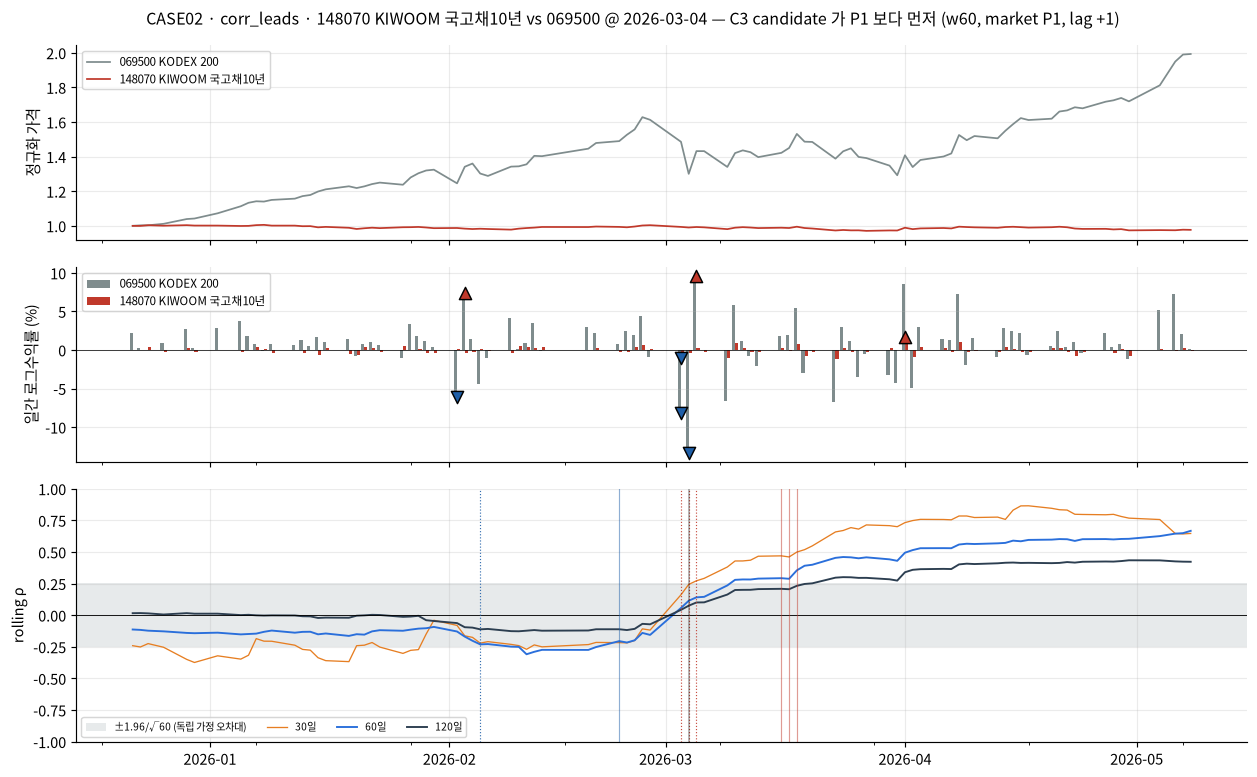

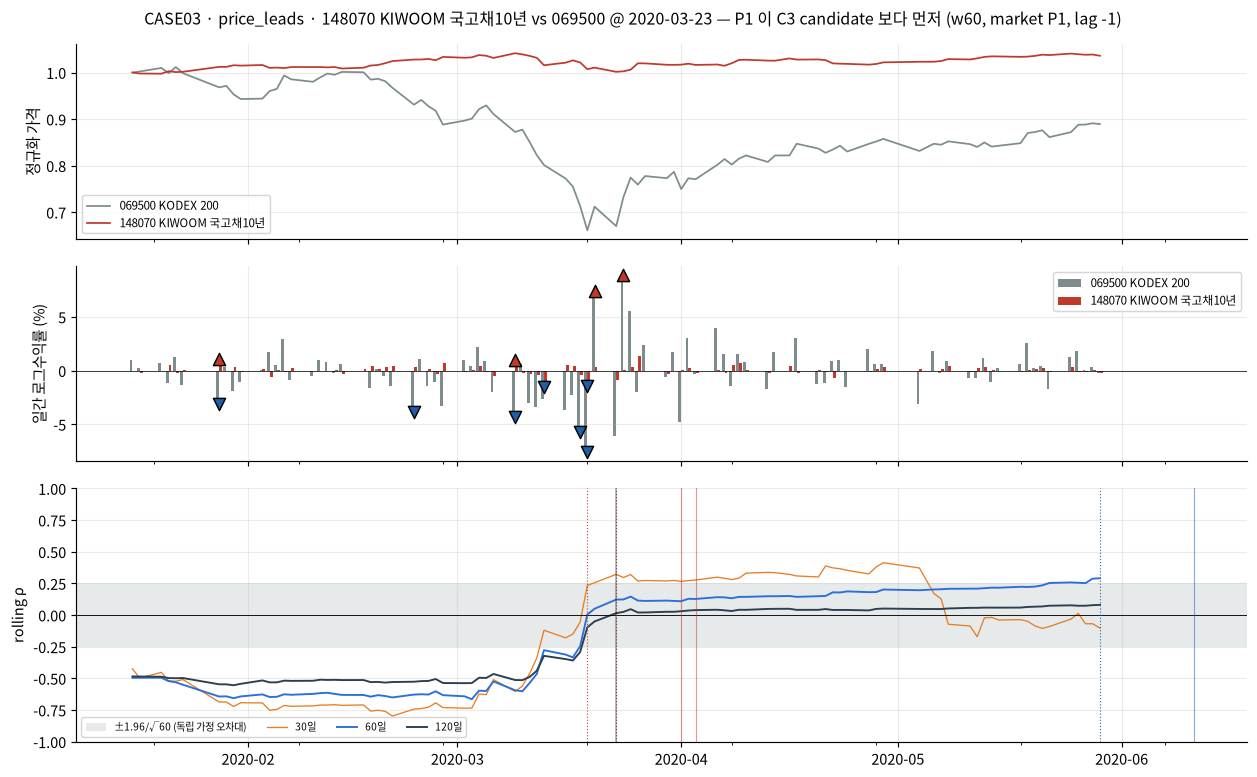

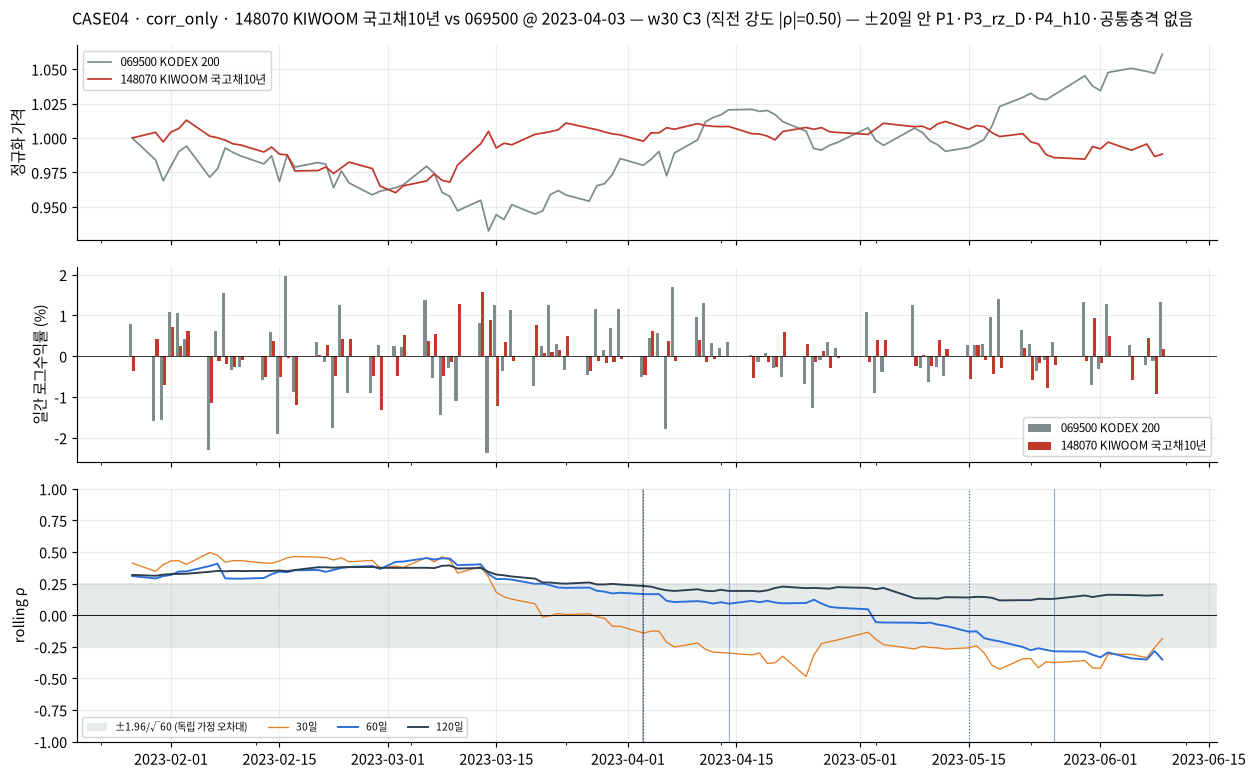

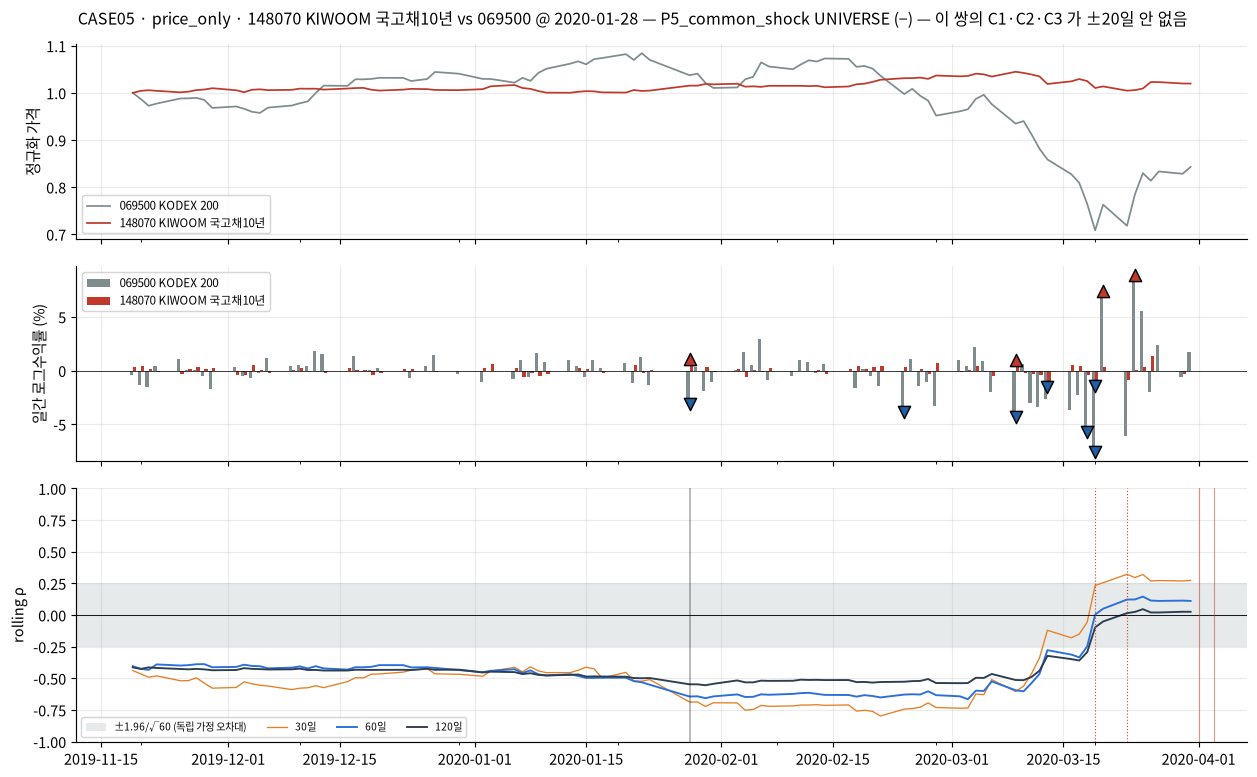

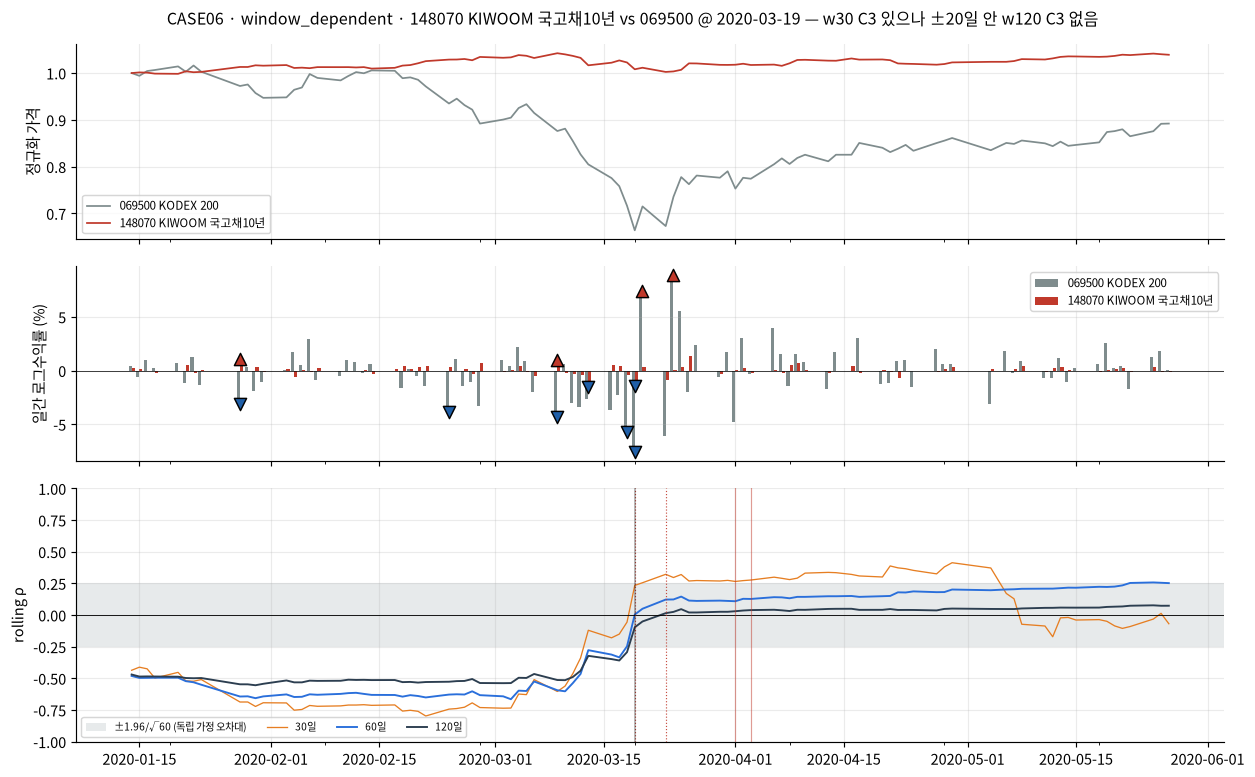

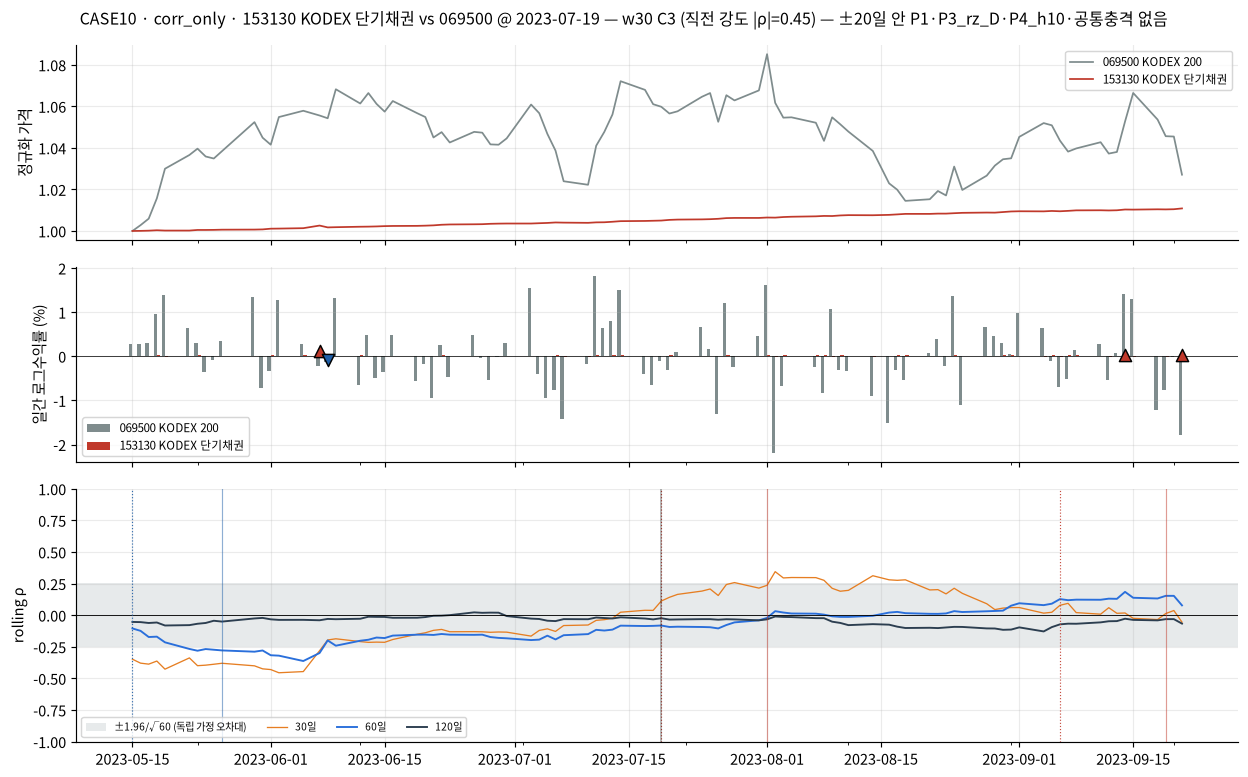

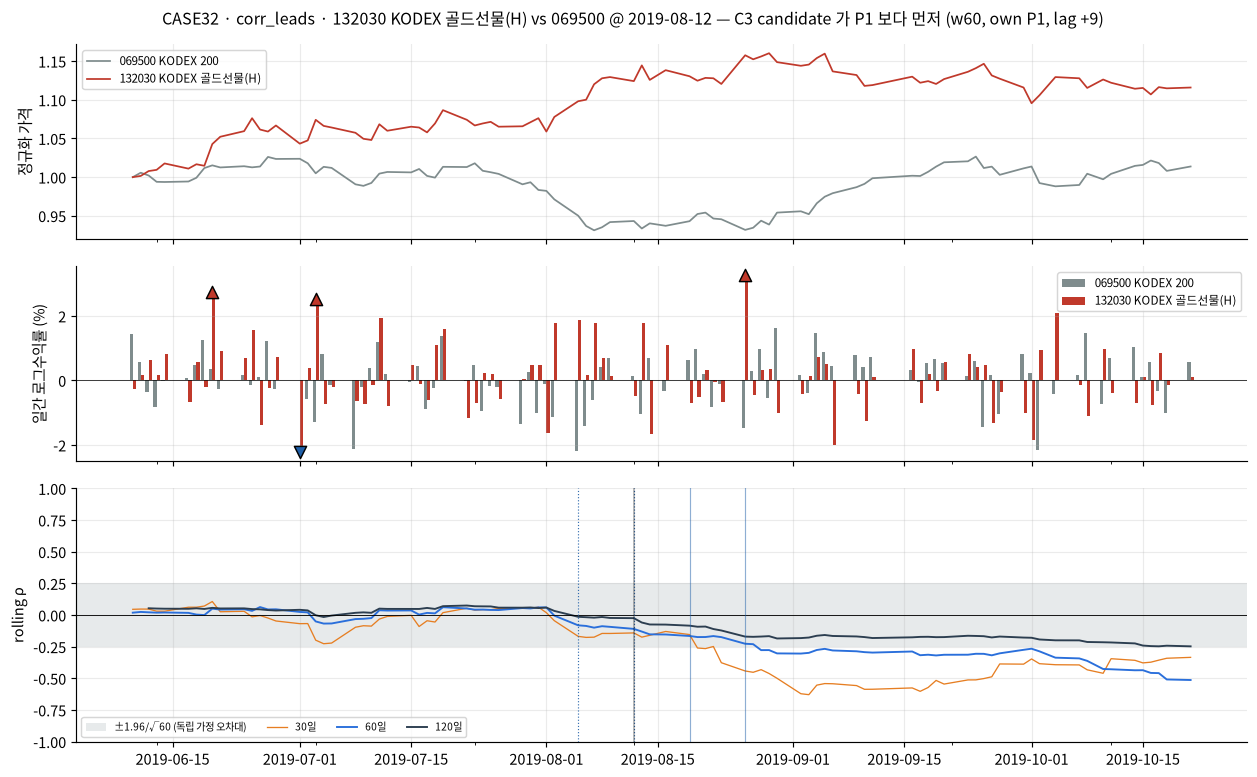

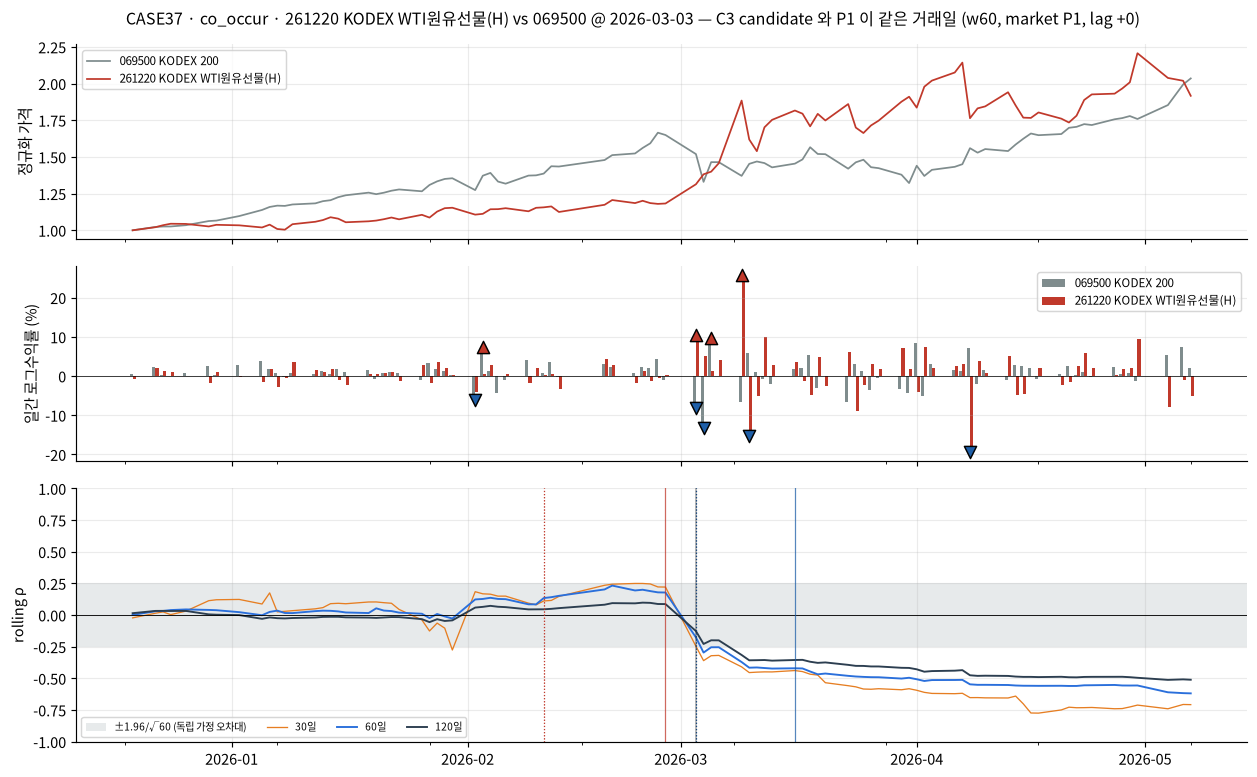

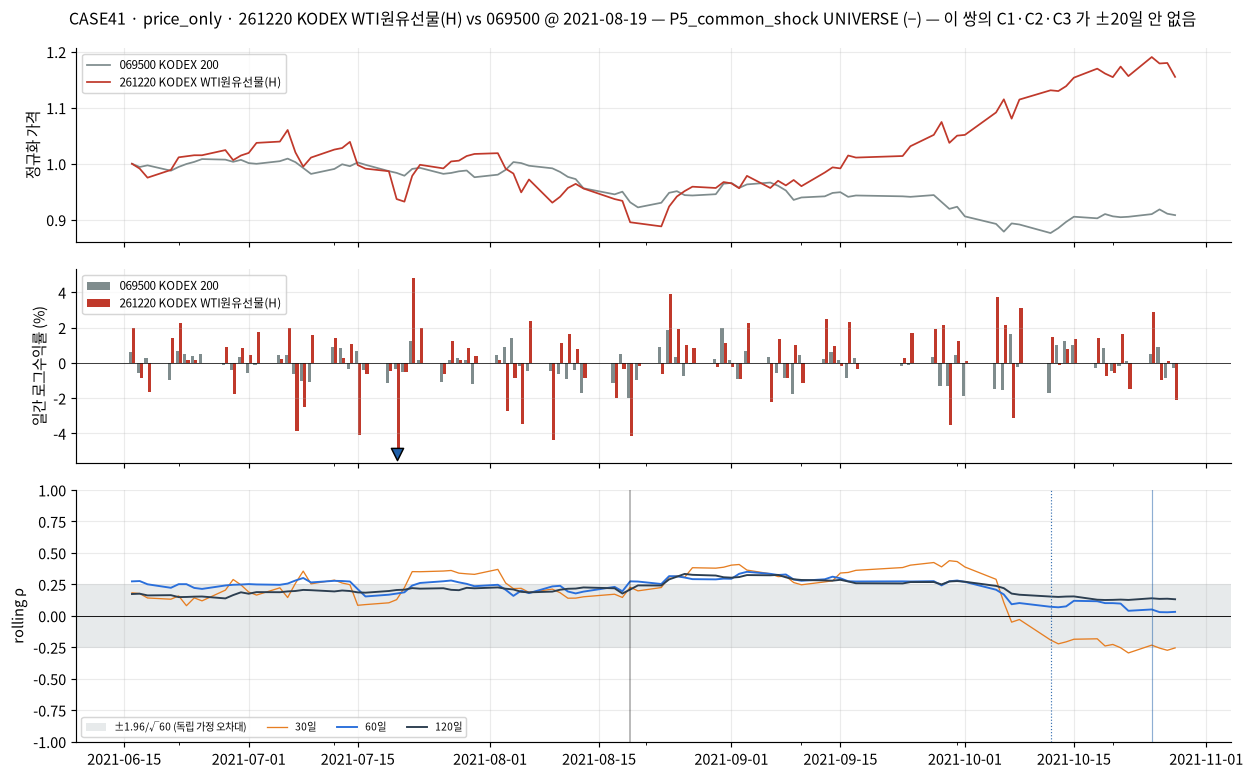

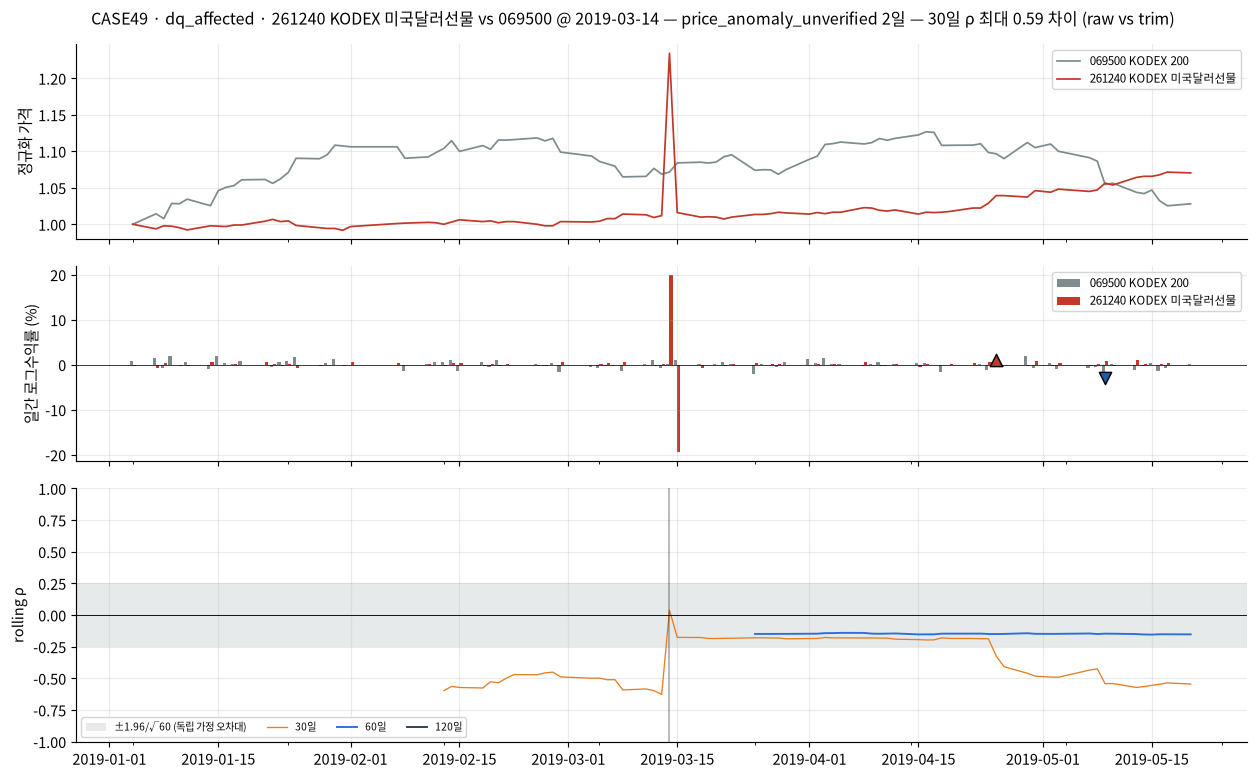

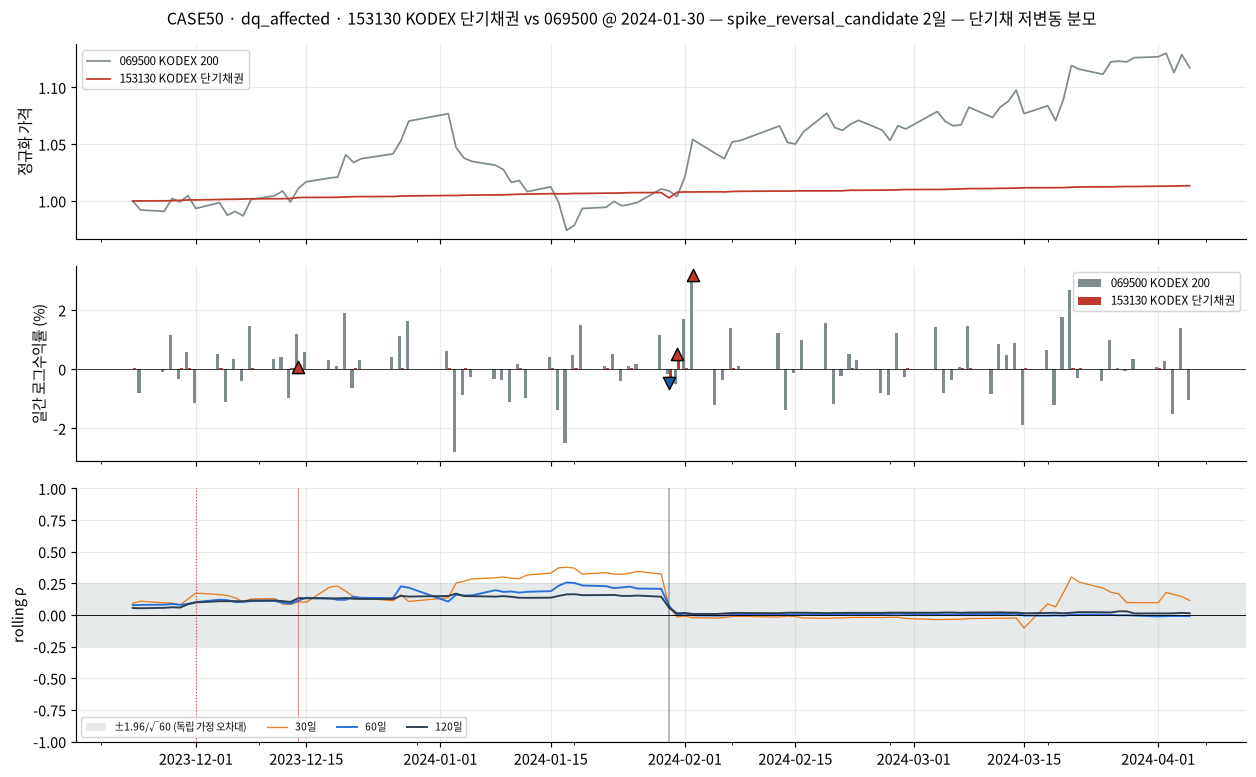

In [12]:
def show_case(cid):
    cr = cases.set_index("case_id").loc[cid]
    t = cr.ticker; center = cr.c_date if pd.notna(cr.c_date) else cr.p_date
    rr_ = rr if cr.case_type == "dq_affected" and t == "261240" else r
    rh = {w: RC.rolling_corr(rr_[t], rr_[REF], w, min_periods=int(np.ceil(.9 * w)))["rho"] for w in (30, 60, 120)}
    cev = c69[(c69.series_id == t) & (c69.method == "pearson") & (c69.definition_id == "C3_sign_regime") & (c69.parameter_set == '{"band": 0.1, "persist": 10}')]
    pev = pe[(pe.series_id.isin([REF, t])) & (pe.definition_id == "P1_vol_scaled")]
    fig = V.case_plot(close, rr_, REF, t, rh, LAB, center, half=45, c_events=cev, p_events=pev,
                      title=f"{cid} · {cr.case_type} · {LAB[t]} vs 069500 @ {pd.Timestamp(center).date()} — {cr.reason}")
    savefig(fig, f"case_{cid}"); plt.show()

SHOW = ["CASE01", "CASE02", "CASE03", "CASE04", "CASE05", "CASE06", "CASE10", "CASE32", "CASE37", "CASE41", "CASE49", "CASE50"]
for cid in SHOW:
    show_case(cid)

### 사례 해석 (그림: 위=정규화 가격, 가운데=일간 수익률 · ▲▼=P1, 아래=30/60/120일 ρ · 점선=C3 candidate · 실선=confirmed)
- **CASE01 co_occur (148070, 2024-08-05)**: 엔캐리 청산 급락일(기존 anchor A2). 069500 −9.6% 와 국고채 +0.9% 가 같은 날 → 이 하루의 큰 음(−)의 곱이 60일 ρ 를 band 아래로 밀었다.
  §6 의 기계적 일치의 전형.
- **CASE02 corr_leads (148070, 2026-03-04 → P1 03-05)**: 상관 후보가 하루 먼저지만 그 03-04 자체가 공통충격일(A3 anchor) — 선행이라기보다 같은 충격의 이틀.
- **CASE03 price_leads (148070, P1 2020-03-20 → C3 03-23)**: 코로나 급락·반등 중 가격이 먼저 움직이고 상관이 뒤따름. 상관이 가격에 *반응*한 사례.
- **CASE04 corr_only (148070, 2023-04-03)**: ±20일 안 069500·148070 의 어떤 가격 사건도 없이 30일 ρ 가 부호를 바꿈 — 조용한 구간의 관계 변화.
- **CASE05 price_only (148070, 공통충격 2020-01-28)**: 시장 공통충격인데 이 쌍의 C1·C2·C3 가 ±20일 안에 없음. 가격 급변이 상관을 바꾸지 않은 사례.
- **CASE06 window_dependent (148070, 2020-03-19)**: 30일 창은 전환을 잡지만 120일 창은 ±20일 안에 전환이 없음 — 긴 창은 같은 충격을 평균에 묻는다.
- **CASE10 corr_only (153130, 2023-07-19)**: 단기채의 전환, 주변에 가격 사건 없음 — A01 §7 의 잡음 우세 구간과 구분하기 어렵다.
- **CASE32 corr_leads (132030 금, 2019-08-12 → 자기 P1 08-26, lag +9)**: 상관 전환 9거래일 뒤 금 급등. 1차 가족 검정에서 금은 유의하지 않다 — 단일 사례로 일반화하지 않는다.
- **CASE37 co_occur (261220 원유, 2026-03-03)**: 2026 원유 −상관 국면 진입과 공통충격이 같은 날.
- **CASE41 price_only (261220, 2021-08-19)**: 공통충격인데 원유–KOSPI 상관 사건 없음.
- **CASE49 dq_affected (261240, 2019-03-14)**: raw 로 그린 그림. 이상치 2일이 30일 ρ 를 0.59 바꿈 → 이 구간의 상관 사건은 해석 불가.
- **CASE50 dq_affected (153130, 2024-01-30)**: spike 후보 2일 — 30일 ρ 최대 0.32 이동(A01 §7).

**존재하지 않은 유형(19건)**: 229200·219480·133690 은 C3 자체가 없어 co_occur·corr_leads·price_leads·corr_only·window_dependent 가 없다(3쌍 × 5 = 15건, A012 §4).
261240 은 C3 가 2건뿐이라 60일 기준 co_occur·corr_leads·price_leads 가 없다(3건).
153130 은 price_only 가 없다 — 모든 공통충격·P1 주변 ±20일에 153130 의 C1·C2·C3 중 하나가 있다(교차가 너무 잦아서이지 관련이 있어서가 아니다).

## 8. 민감도 — 창 · 규칙 · DQ · 노출 중복 · 2026

In [13]:
w_t = tt[(tt.c_time == "candidate_at") & (tt.max_lag == 10) & tt.c_def.str.startswith(("C1", "C2", "C3"))]
display(w_t.groupby(["c_def", "window"]).apply(lambda g: (g.p_value < .05).mean()).unstack().round(3).rename_axis(columns="window → share p<0.05 (L=10)"))
display(tt[(tt.c_time == "candidate_at") & (tt.max_lag == 10)].groupby("p_def").apply(lambda g: (g.p_value < .05).mean()).round(3).to_frame("share p<0.05 (L=10)"))
display(ck["dq_event_sensitivity"].drop(columns=["run_id", "input_data_version"]))
display(ck["exposure_dedup_check"].drop(columns=["run_id", "input_data_version"]))
print("069500 vs 102110 P1:", ck["manifest"]["metrics"]["exposure_P1"])
pr = ck["period_results"]
pt = pr.groupby("period")[["n_days", "n_C3", "n_P1_market_bothdir", "n_C3_with_P1_within10"]].sum()
pt["C3_per_1000_pair_days"] = pt.n_C3 / pt.n_days * 1000
pt["P1_per_1000_pair_days"] = pt.n_P1_market_bothdir / pt.n_days * 1000
pt["share_C3_near_P1"] = pt.n_C3_with_P1_within10 / pt.n_C3
display(pt.round(3))
assert ck["manifest"]["metrics"]["exposure_P1"]["P1_union"] == 29 and pt.loc["holdout_2026", "n_C3"] == 9
assert 3.2 < pt.loc["holdout_2026", "P1_per_1000_pair_days"] / pt.loc["dev_2019_2024", "P1_per_1000_pair_days"] < 3.4

window → share p<0.05 (L=10),120,30,60
c_def,,,
C1_zero_cross,0.139,0.038,0.011
C2_large_change,0.104,0.113,0.055
C3_b0.000_k5,0.072,0.011,0.062
C3_b0.100_k10,0.078,0.062,0.117
C3_b0.100_k20,0.028,0.058,0.044
C3_b0.200_k10,0.033,0.053,0.033


,share p<0.05 (L=10)
p_def,
P1_vol_scaled,0.092
P2_quantile_exp,0.064
P2_quantile_full,0.060
P3_rz_A,0.074
P3_rz_D,0.054
P3_rz_eda,0.064
P4_cum_h10,0.054
P4_cum_h20,0.052
P4_cum_h5,0.088


,ticker,window,variant,n_zero_cross,n_C3,zero_cross_2019
0,261240,30,raw,12,2,2
1,261240,30,dq_trim_canonical,10,2,0
2,261240,60,raw,2,0,0
3,261240,60,dq_trim_canonical,2,0,0
4,261240,120,raw,0,0,0
5,261240,120,dq_trim_canonical,0,0,0


,ticker,window,n_C3_ref069500,n_C3_ref102110,n_069500_with_102110_within2d
0,148070,30,21,21,17
1,148070,60,13,13,11
2,148070,120,7,7,6
3,153130,30,13,13,12
4,153130,60,11,11,11
5,153130,120,6,6,6
6,229200,30,0,0,0
7,229200,60,0,0,0
8,229200,120,0,0,0
9,219480,30,0,0,0


069500 vs 102110 P1: {'P1_069500': 28, 'P1_102110': 27, 'P1_both': 26, 'P1_union': 29, 'naive_sum_double_count': 55}


,n_days,n_C3,n_P1_market_bothdir,n_C3_with_P1_within10,C3_per_1000_pair_days,P1_per_1000_pair_days,share_C3_near_P1
period,,,,,,,
dev_2019_2024,35424,80,408,16,2.258,11.518,0.200
holdout_2026,4416,9,168,9,2.038,38.043,1.000
val_2025,5808,22,96,9,3.788,16.529,0.409


### 해석
- **창·규칙**: L=10 에서 p<0.05 비율은 창·C 정의에 따라 몇 % 포인트씩 다르지만 일관된 방향(짧은 창이 항상 유리 등)이 없다 — 어느 창도 '우연 이상'을 안정적으로 만들지 않는다.
- **P 정의**: 정의마다 비율이 다르다. 실시간 정의(P1·P2_exp·P3)와 look-ahead/사후 정의(P2_full·P4·q99) 사이에 체계적 우위가 없다.
- **DQ (261240)**: raw 의 30일 0선 교차 12 중 2019 년 2번은 trim 에서 사라진다. 이상치 구간의 상관 사건은 해석 불가 유형으로 분리했다.
- **노출 중복**: 069500 과 102110 의 P1 은 각 28·27일, 겹침 26, 합집합 29 — 따로 세면 55 로 **거의 두 배**. C3 도 102110 기준으로 바꾸면 대부분(±2일 안) 같은 날이 나온다.
  같은 KOSPI200 exposure 는 사건 1건으로 센다.
- **2026 (관찰 구간)**: 1,000 쌍-일당 P1 이 38.0 으로 개발 구간(11.5)의 **3.3배**(고변동). 2026 의 C3 9건이 전부 ±10일 안에 P1 을 갖지만, **P1 밀도가 높아 우연 근접도 많다** — 귀무검정 없이 비율만 보면 2026 이 '잘 맞는' 것처럼 보이는 함정. 2026 에 맞춰 기준을 조정하지 않았다.

> **재구성 질문** — 2026 에서 C3 의 100% 가 P1 근처라는 사실이 탐지 능력의 증거가 아닌 이유를 기저율(base rate)로 설명하라.

## 9. 연구 결론 — 결론 질문 9개에 대한 답

| # | 질문 | 답 | 근거 |
|---|---|---|---|
| 1 | KOSPI200 과 장·단기 채권의 관계 변화가 뚜렷한가? | **국고채10년은 뚜렷하다**: 연도별 −0.40(2019) ~ +0.37(2026), 60일 C3 13회. **단기채는 아니다**: 시간의 90% 가 근사 오차대 안 | A01 §2·§4·§5 |
| 2 | rolling window 에 얼마나 민감한가? | 매우 민감. 148070 교차 55/45/41, C3 21/13/7 (30/60/120). 긴 창은 늦고 평균화(CASE06) | A01 §4, CASE06 |
| 3 | 0선 교차가 유의미한 후보 사건인가? | **단독으로는 아니다.** 독립 난수도 수십 번 교차하고, 교차의 약 절반은 하루 수익률이 만든다. 지속성·크기 필터(C3) 후에만 후보 | A01 §3·§6 |
| 4 | 단기채 반복 0 수익률의 왜곡? | 0→NaN 시 30일 교차 137 → 97, n_eff 30 → 25.0. spike 후보 2일이 ρ 를 0.32 이동 | A01 §7 |
| 5 | 해외주식·원자재·선물은 채권과 어떻게 다른가? | 주식(229200·219480·133690)·달러는 부호 고정(C3 0건). 금·원유는 부호가 바뀌고(원유 2026 −0.30), 장기 전환은 채권보다 적다. 비동기 왜곡은 약함 | A012 §2~§6 |
| 6 | 가격 급등 후보와 상관 변화 후보는 얼마나 일치하는가? | 같은 날(L=0)만 우연 이상(p<0.05 11.2%), L=20 5.1%. 1차 가족 BH 생존 3/586 (모두 사건 2~6개). 같은 날 일치는 사건일 제거 시 사라짐(9/48 → 0/48) | §5·§6 |
| 7 | 정의 차이는 무엇을 측정하나? | robust-z 3 정의 Jaccard 0.73~0.85 — 같은 '급등'도 MAD 정의로 1/4 이 바뀜. 일간 vs 누적 정의는 거의 다른 날(0.02~0.09). C2 는 크기, C3 는 부호, C5 는 추정량 강건성 | §2·§3 |
| 8 | 현재 데이터로 내릴 수 없는 결론? | 상관 전환의 **인과·선행성**, 2026 의 '새 관계' 여부(고변동 국면과 구분 불가), 실시간 탐지 성능(Ground Truth 부재), 가격조정 영향(미확정) | §1·§8, A00 §5 |
| 9 | CUSUM 논문 결과와 연결할 때 보존할 정의 차이? | (a) `candidate_at` vs `available_at` (b) 일간 로그수익률 logdiff · `dq_trim_canonical` (c) KOSPI200 exposure dedup (d) robust-z 정의 ID (e) 사후 라벨(P4·look-ahead) 표시 (f) 같은 날 기계적 중복 — CUSUM 경보와 비교할 때도 같은 관측치 중복을 제거해야 함 | Track C 인계 명세 |

**최종 실증 결론**: 이 데이터에서 KOSPI200 과 다른 자산의 rolling 상관 전환은 (i) 채권·금·원유에서 실재하는 국면 변화를 보이지만 (ii) 0선 교차 자체는 대부분 잡음이고,
(iii) 가격 급등·급락과의 시간적 근접은 **같은 날 큰 수익률이 상관을 기계적으로 움직이는 효과**를 빼면 우연 수준과 구분되지 않는다.
**상관관계 전환을 급등의 Ground Truth 나 조기 경보로 쓰는 근거는 발견되지 않았다.** 이것은 '효과 없음의 증명'이 아니라, 현재 정의·데이터·검정력에서의 부정적 결과다.

In [14]:
final = {"lag0_share_p05": float((tt[tt.max_lag == 0].p_value < .05).mean()), "lag20_share_p05": float((tt[tt.max_lag == 20].p_value < .05).mean()),
         "global_q10": int((tt.q_value_bh < .10).sum()), "primary_q10": int((tt[tt.primary_family].q_value_bh_primary < .10).sum()),
         "masked_lag0_p05": f"{int(mrs.loc[0, 'n_p05_orig'])}/48 → {int(mrs.loc[0, 'n_p05_masked'])}/48", "cases_found": int(cases.found.sum()),
         "cases_absent": int((~cases.found).sum()), "C5_events": len(c5p), "matched_lag0_share": LAG0}
display(pd.Series(final, name="A02 final"))

lag0_share_p05           0.111749
lag20_share_p05          0.050795
global_q10                    299
primary_q10                     3
masked_lag0_p05       9/48 → 0/48
cases_found                    32
cases_absent                   19
C5_events                      51
matched_lag0_share       0.308411
Name: A02 final, dtype: object